# RoboJEPA: one latent world model for many robots

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/action/robojepa.ipynb)

[RoboJEPA](https://arxiv.org/abs/2610.10515) trains an action-conditioned predictor in the latent space of a frozen V-JEPA 2.1 encoder, on data from 12 robot embodiments with several cameras each. Every timestep holds the patch tokens of all views, one action token and one proprioception token, and actions and states are projected separately for each embodiment. Training uses teacher forcing plus short autoregressive rollouts, as in [V-JEPA 2-AC](https://arxiv.org/abs/2506.09985).

Here there are **two embodiments** that share a body but not an action space (the second robot's controls are rotated 90°), seen by **two cameras**.

In [ ]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"

In [1]:
import torch
import torch.nn.functional as F
from torch import nn

from torch_world import plots
from torch_world.envs import PointMass, run_policy
from torch_world.models import RoboJEPA
from torch_world.planning import CEM

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
ROTATE = torch.tensor([[0.0, 1.0], [-1.0, 0.0]], device=device)

## Data from two embodiments and two cameras
Camera 2 sees the scene mirrored.

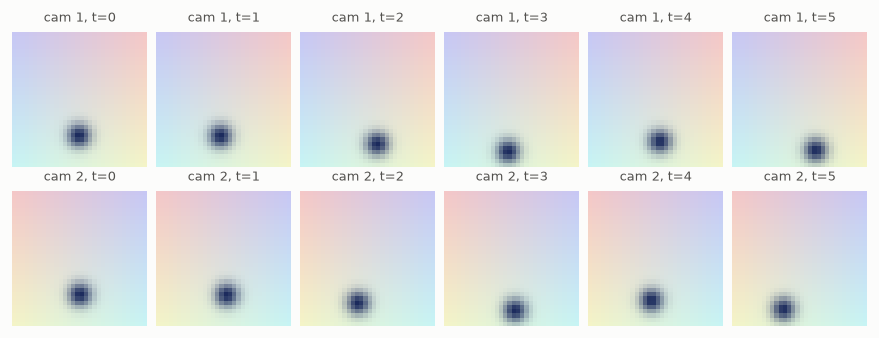

In [2]:
def apply(actions, embodiment):
    return torch.where(embodiment[:, None] == 1, actions @ ROTATE, actions)


def cameras(pixels):
    return torch.stack([pixels, pixels.flip(-1)], dim=-4)


def collect(n, steps):
    env = PointMass(batch_size=n, size=32, device=device)
    embodiment = torch.arange(n, device=device) % 2
    frames, states, actions = [env.reset()], [env.state], []
    for _ in range(steps):
        a = torch.rand(n, 2, device=device) * 2 - 1
        frames.append(env.step(apply(a, embodiment)))
        states.append(env.state)
        actions.append(a)
    actions.append(torch.zeros_like(a))
    return cameras(torch.stack(frames, 1)), torch.stack(actions, 1), torch.stack(states, 1), embodiment


frames, *_ = collect(1, 5)
plots.images(frames[0].transpose(0, 1).flatten(0, 1), [f"cam {v + 1}, t={t}" for v in range(2) for t in range(6)], ncols=6)

## Model
Raw 8×8 pixel patches stand in for the frozen V-JEPA 2.1 encoder.

In [3]:
class Patchify(nn.Module):
    def forward(self, x):
        return F.pixel_unshuffle(x, 8).flatten(2).transpose(1, 2)


model = RoboJEPA(
    embed_dim=192, action_dim=2, state_dim=2, num_views=2, num_embodiments=2,
    predictor_dim=256, depth=6, num_heads=4, window=4, rollout_steps=2, encoder=Patchify(),
).to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M parameters")

4.84M parameters


## Train

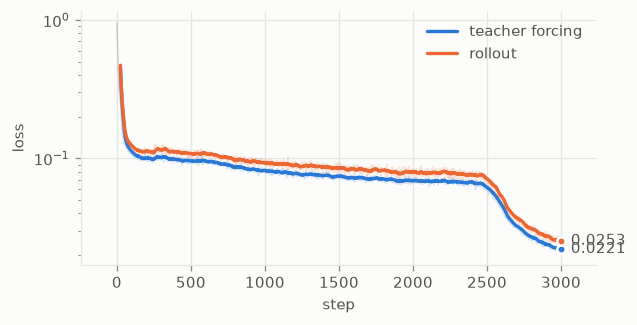

In [4]:
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.04)
log = {"teacher forcing": [], "rollout": []}
for step in range(3000):
    frames, actions, states, embodiment = collect(128, 7)
    out = model(model.encode(frames, (4, 4)), actions, states, embodiment)
    opt.zero_grad()
    out["loss"].backward()
    opt.step()
    log["teacher forcing"].append(out["tf_loss"].item())
    log["rollout"].append(out["rollout_loss"].item())
model.eval()
plots.curves(log)

## Plan for each embodiment
One planner and one model. The embodiment id is the only thing that changes how actions are read.

robot A: success rate (within 0.1) 0.81


robot B (rotated controls): success rate (within 0.1) 0.75


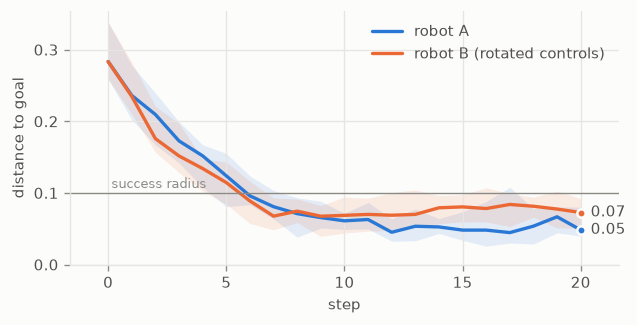

In [5]:
planner = CEM(horizon=5, action_dim=2, num_samples=256, num_elites=32, iterations=10, bounds=(-1, 1))
runs, examples = {}, {}
for e, name in enumerate(["robot A", "robot B (rotated controls)"]):
    env = PointMass(batch_size=16, size=32, device=device)
    env.reset(generator=torch.Generator().manual_seed(1))
    goals = env.sample_goals((0.2, 0.5), generator=torch.Generator().manual_seed(2))
    ids = torch.full((16,), e, device=device)
    goal = model.encode(cameras(env.render(goals))[:, None], (4, 4))[:, 0]

    def policy(obs, env=env, goal=goal, ids=ids):
        z = model.encode(cameras(obs)[:, None], (4, 4))
        return apply(planner(model, z, goal, states=env.state[:, None], embodiment=ids)[:, 0], ids)

    paths = run_policy(env, policy, steps=20)
    runs[name] = (paths - goals[:, None]).norm(dim=-1)
    examples[name] = paths[:4], goals[:4]
    print(f"{name}: success rate (within 0.1) {(runs[name][:, -1] < 0.1).float().mean():.2f}")
plots.distances(runs, radius=0.1)

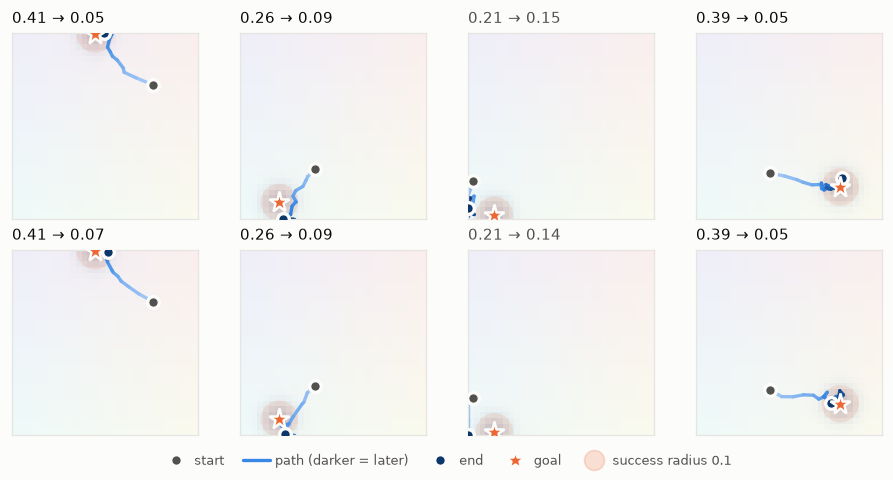

In [6]:
paths = torch.cat([p for p, _ in examples.values()])
goals = torch.cat([g for _, g in examples.values()])
plots.trajectories(paths, goals, background=PointMass(batch_size=8, size=32, device=device).render(goals))